In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [84]:
df = pd.read_csv("Hours and Scores.csv")

In [85]:
df.head()

,Unnamed: 0,Hours,Scores
0,"2.5,21",2.5,21
1,"5.1,47",5.1,47
2,"3.2,27",3.2,27
3,"8.5,75",8.5,75
4,"3.5,30",3.5,30


In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  25 non-null     object 
 1   Hours       25 non-null     float64
 2   Scores      25 non-null     int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 732.0+ bytes


In [87]:
df.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


In [88]:
df.isnull().sum()

,0
Unnamed: 0,0
Hours,0
Scores,0


In [89]:
df.duplicated().sum()

np.int64(0)

In [90]:
df = df.drop_duplicates()

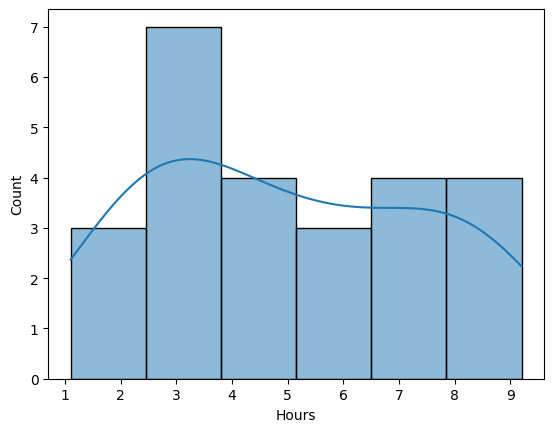

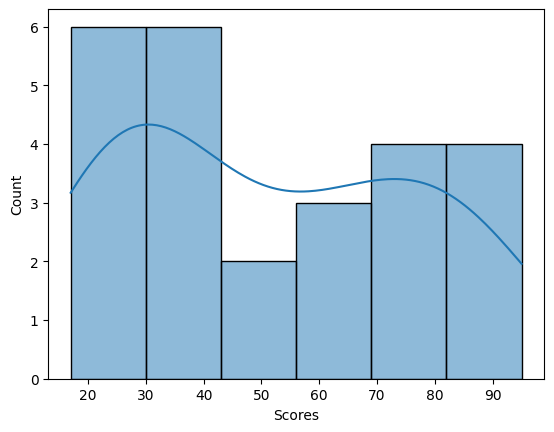

In [91]:
sns.histplot(df["Hours"], kde=True)
plt.show()

sns.histplot(df["Scores"], kde=True)
plt.show()

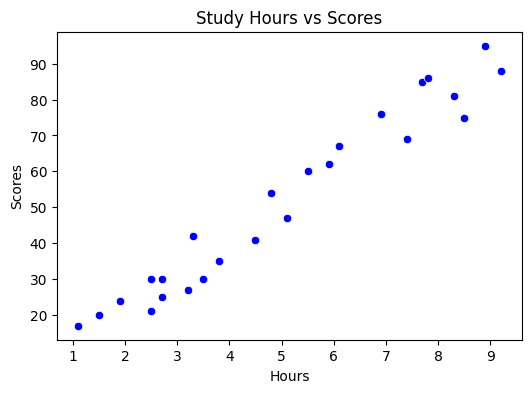

In [92]:
plt.figure(figsize=(6,4))

sns.scatterplot(data=df,
                x="Hours",
                y="Scores",
                color="blue")

plt.title("Study Hours vs Scores")
plt.show()

In [93]:
print(df.head())
print(df.columns)
print(df.dtypes)

  Unnamed: 0  Hours  Scores
0     2.5,21    2.5      21
1     5.1,47    5.1      47
2     3.2,27    3.2      27
3     8.5,75    8.5      75
4     3.5,30    3.5      30
Index(['Unnamed: 0', 'Hours', 'Scores'], dtype='object')
Unnamed: 0     object
Hours         float64
Scores          int64
dtype: object


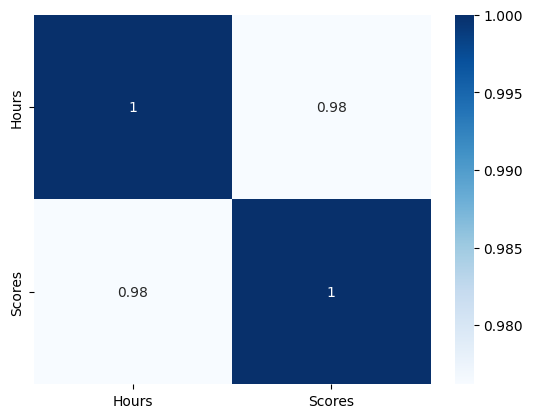

In [94]:
df = df.drop(columns=['Unnamed: 0'])

sns.heatmap(df.corr(), annot=True, cmap="Blues")
plt.show()

In [95]:
X = df[["Hours"]]

In [96]:
y = df["Scores"]

In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [98]:
lr = LinearRegression()

lr.fit(X_train, y_train)

LinearRegression()

In [99]:
y_pred_lr = lr.predict(X_test)


In [100]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)

mse_lr = mean_squared_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mse_lr)

r2_lr = r2_score(y_test, y_pred_lr)

print("MAE :", mae_lr)
print("MSE :", mse_lr)
print("RMSE:", rmse_lr)
print("R2 :", r2_lr)

MAE : 3.9207511902099244
MSE : 18.943211722315272
RMSE: 4.352380006653288
R2 : 0.9678055545167994


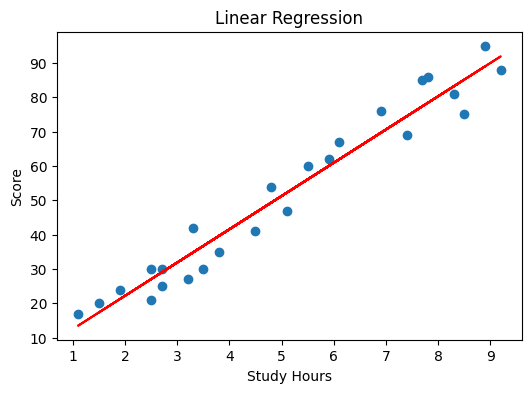

In [101]:
plt.figure(figsize=(6,4))

plt.scatter(X, y)

plt.plot(X,
         lr.predict(X),
         color='red')

plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.title("Linear Regression")

plt.show()

In [102]:
dt = DecisionTreeRegressor(
    random_state=42,
    max_depth=3
)

dt.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=42)

In [103]:
y_pred_dt = dt.predict(X_test)

In [104]:
X_grid = np.arange(X.values.min(),
                   X.values.max(),
                   0.01)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


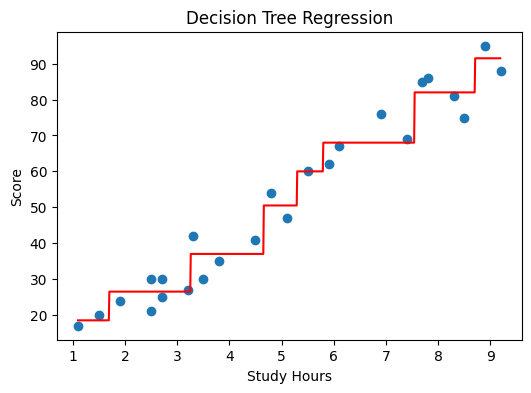

In [105]:
X_grid = np.arange(X['Hours'].min(),
                   X['Hours'].max(),
                   0.01)

X_grid = X_grid.reshape(-1, 1)

plt.figure(figsize=(6,4))
plt.scatter(X, y)

plt.plot(X_grid,
         dt.predict(X_grid),
         color='red')

plt.title("Decision Tree Regression")
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.show()

In [106]:
comparison = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Decision Tree"
    ],

    "MAE":[
        mae_lr,
        mae_dt
    ],

    "RMSE":[
        rmse_lr,
        rmse_dt
    ],

    "R2 Score":[
        r2_lr,
        r2_dt
    ]

})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.920751,4.352380,0.967806
1,Decision Tree,4.800000,5.357238,0.951224


In [107]:
best = comparison.sort_values(
    by="R2 Score",
    ascending=False
)

best

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.920751,4.352380,0.967806
1,Decision Tree,4.800000,5.357238,0.951224


In [111]:
# Predict Score for a Student

study_hours = 9

predicted_score = lr.predict([[study_hours]])[0]

print("=" * 45)
print("      STUDENT SCORE PREDICTION")
print("=" * 45)
print(f"Study Hours     : {study_hours} hours")
print(f"Predicted Score : {predicted_score:.2f} marks")
print("=" * 45)

      STUDENT SCORE PREDICTION
Study Hours     : 9 hours
Predicted Score : 89.97 marks


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
